## DATA PREPROCESSING AND FEATURE ENGINEERING IN MACHINE LEARNING

In [1]:
## importing required libraries 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
df = pd.read_csv(r"C:\Users\deytu\Desktop\study\EXCELR\Assignment\Data and Docs\Data Trasformation\adult_with_headers (1).csv")
df

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [4]:
df.describe()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


### Observations
* Age and hours_per_week are fairly centered around their means and medians.
* capital_gain and capital_loss are highly skewed because most values are zero while a few observations have very large values.
* fnlwgt shows considerable variability across individuals.
* The dataset contains potential outliers in capital_gain, capital_loss, and hours_per_week, which may require further investigation during data preprocessing.

In [5]:
df.isna().sum() ## checkin for missing values 

age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
income            0
dtype: int64

In [6]:
df_categorical  = df.select_dtypes(include= "object")

In [7]:
df_categorical

,workclass,education,marital_status,occupation,relationship,race,sex,native_country,income
0,State-gov,Bachelors,Never-married,Adm-clerical,Not-in-family,White,Male,United-States,<=50K
1,Self-emp-not-inc,Bachelors,Married-civ-spouse,Exec-managerial,Husband,White,Male,United-States,<=50K
2,Private,HS-grad,Divorced,Handlers-cleaners,Not-in-family,White,Male,United-States,<=50K
3,Private,11th,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,United-States,<=50K
4,Private,Bachelors,Married-civ-spouse,Prof-specialty,Wife,Black,Female,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...
32556,Private,Assoc-acdm,Married-civ-spouse,Tech-support,Wife,White,Female,United-States,<=50K
32557,Private,HS-grad,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,United-States,>50K
32558,Private,HS-grad,Widowed,Adm-clerical,Unmarried,White,Female,United-States,<=50K
32559,Private,HS-grad,Never-married,Adm-clerical,Own-child,White,Male,United-States,<=50K


### Missing value handling 

In [8]:
columns = ["workclass","education","marital_status","occupation","relationship","race","sex","native_country","income"]

for col in columns:
    print(df[col].value_counts())

workclass
Private             22696
Self-emp-not-inc     2541
Local-gov            2093
?                    1836
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64
education
HS-grad         10501
Some-college     7291
Bachelors        5355
Masters          1723
Assoc-voc        1382
11th             1175
Assoc-acdm       1067
10th              933
7th-8th           646
Prof-school       576
9th               514
12th              433
Doctorate         413
5th-6th           333
1st-4th           168
Preschool          51
Name: count, dtype: int64
marital_status
Married-civ-spouse       14976
Never-married            10683
Divorced                  4443
Separated                 1025
Widowed                    993
Married-spouse-absent      418
Married-AF-spouse           23
Name: count, dtype: int64
occupation
Prof-specialty       4140
Craft-repair         4099
Exec-managerial      

We can observe that many columns have "?" we must find all the columns with this value and replace it 

In [9]:
for col in columns:
    print(col,":",(df[col] == " ?").sum())

workclass : 1836
education : 0
marital_status : 0
occupation : 1843
relationship : 0
race : 0
sex : 0
native_country : 583
income : 0


we can see from above Workclass Occupation and Native_country has these 

In [10]:
## now for numerical columns 
num_col = ["age","fnlwgt","education_num","capital_gain","capital_loss","hours_per_week"]
for col in num_col:
    print(col,":",(df[col] == " ?").sum())

age : 0
fnlwgt : 0
education_num : 0
capital_gain : 0
capital_loss : 0
hours_per_week : 0


In [11]:
# hence we only need to handle the categorical columns  
df.replace(" ?", np.nan , inplace =True)
for col in columns:
    print(col ,":",(df[col]==" ?").sum())

workclass : 0
education : 0
marital_status : 0
occupation : 0
relationship : 0
race : 0
sex : 0
native_country : 0
income : 0


In [12]:
## We have successfully replaced all " ?" with NaN
df.isna().sum()

age                  0
workclass         1836
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     583
income               0
dtype: int64

In [13]:
## Now since Workclass and Occupation has NaN in excess of 5% we should replace it with unknown and for native_country the NaN values are under 2% so we will replace it with mode 
df["workclass"] = df["workclass"].fillna("unknown")
df["occupation"] = df["occupation"].fillna("unknown")
df["native_country"] = df["native_country"].fillna(df["native_country"].mode()[0])
df.isna().sum()

age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
income            0
dtype: int64

In [14]:
## We have succesfully handled all the missing values now we should move towards scaling 

### Scaling Numerical Columns

In [15]:
df_Std_scaled = df.copy()
from sklearn.preprocessing import StandardScaler
Sscaler = StandardScaler()
df_Std_scaled[num_col] = Sscaler.fit_transform(df[num_col])
df_Std_scaled.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,0.030671,State-gov,-1.063611,Bachelors,1.134739,Never-married,Adm-clerical,Not-in-family,White,Male,0.148453,-0.21666,-0.035429,United-States,<=50K
1,0.837109,Self-emp-not-inc,-1.008707,Bachelors,1.134739,Married-civ-spouse,Exec-managerial,Husband,White,Male,-0.145920,-0.21666,-2.222153,United-States,<=50K
2,-0.042642,Private,0.245079,HS-grad,-0.420060,Divorced,Handlers-cleaners,Not-in-family,White,Male,-0.145920,-0.21666,-0.035429,United-States,<=50K
3,1.057047,Private,0.425801,11th,-1.197459,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,-0.145920,-0.21666,-0.035429,United-States,<=50K
4,-0.775768,Private,1.408176,Bachelors,1.134739,Married-civ-spouse,Prof-specialty,Wife,Black,Female,-0.145920,-0.21666,-0.035429,Cuba,<=50K


In [16]:
## Using min max scaler
df_mmx_scaled = df.copy()
from sklearn.preprocessing import MinMaxScaler
MMXscaler =  MinMaxScaler()
df_mmx_scaled[num_col] = MMXscaler.fit_transform(df_mmx_scaled[num_col])
df_mmx_scaled.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,0.301370,State-gov,0.044302,Bachelors,0.800000,Never-married,Adm-clerical,Not-in-family,White,Male,0.02174,0.0,0.397959,United-States,<=50K
1,0.452055,Self-emp-not-inc,0.048238,Bachelors,0.800000,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.00000,0.0,0.122449,United-States,<=50K
2,0.287671,Private,0.138113,HS-grad,0.533333,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.00000,0.0,0.397959,United-States,<=50K
3,0.493151,Private,0.151068,11th,0.400000,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.00000,0.0,0.397959,United-States,<=50K
4,0.150685,Private,0.221488,Bachelors,0.800000,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.00000,0.0,0.397959,Cuba,<=50K


## When to Use Standard Scaling and Min-Max Scaling

### Standard Scaling (StandardScaler)

Standard Scaling transforms the data so that it has a mean of 0 and a standard deviation of 1.

#### Preferred Scenarios:
- When the data follows a normal or approximately normal distribution.
- When using machine learning algorithms that are sensitive to feature scales, such as:
  - Logistic Regression
  - Support Vector Machines (SVM)
  - K-Nearest Neighbors (KNN)
  - Principal Component Analysis (PCA)
  - Neural Networks

#### Why?
- It standardizes the features around a common scale.
- It reduces the impact of different measurement units.
- It works well when outliers are not extreme.


### Min-Max Scaling (MinMaxScaler)

Min-Max Scaling transforms data to a fixed range, usually between 0 and 1.

#### Preferred Scenarios:
- When the data does not follow a normal distribution.
- When features need to be bounded within a specific range.
- When using algorithms such as:
  - Neural Networks
  - Gradient Descent-based models
  - Distance-based algorithms where a fixed range is beneficial

#### Why?
- It preserves the original distribution of the data.
- It ensures all features have the same scale.
- It is useful when the model requires input values within a specific range.

---

### Encolding Techniques
#### One-Hot Encoding 

In [17]:
## first we check numeber of categories in each column 
cat_columns = ["workclass","education","marital_status","occupation","relationship","race","sex","native_country","income"]
for col in cat_columns:
    print(col,"category count:",(df[col].value_counts()).count())

workclass category count: 9
education category count: 16
marital_status category count: 7
occupation category count: 15
relationship category count: 6
race category count: 5
sex category count: 2
native_country category count: 41
income category count: 2


In [18]:
# we have 3 columns "race","sex","income" with 5 or less categories hence we can apply onehotencoding here 
cat_col1 = ["race","sex","income"]
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder(sparse_output = False)# for easier entry to pandas 
ohe_array = ohe.fit_transform(df[cat_col1])
ohe_df = pd.DataFrame(ohe_array, columns = ohe.get_feature_names_out(cat_col1))
df_ohe1 = df.drop(columns = ["race","sex","income"])
df_ohe = pd.concat([df_ohe1,ohe_df], axis = 1)
df_ohe

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,capital_gain,capital_loss,...,native_country,race_ Amer-Indian-Eskimo,race_ Asian-Pac-Islander,race_ Black,race_ Other,race_ White,sex_ Female,sex_ Male,income_ <=50K,income_ >50K
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,2174,0,...,United-States,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,0,0,...,United-States,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,0,0,...,United-States,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,0,0,...,United-States,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,0,0,...,Cuba,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,0,0,...,United-States,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,0,0,...,United-States,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,0,0,...,United-States,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,0,0,...,United-States,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0


In [19]:
df_ohe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       32561 non-null  int64  
 1   workclass                 32561 non-null  object 
 2   fnlwgt                    32561 non-null  int64  
 3   education                 32561 non-null  object 
 4   education_num             32561 non-null  int64  
 5   marital_status            32561 non-null  object 
 6   occupation                32561 non-null  object 
 7   relationship              32561 non-null  object 
 8   capital_gain              32561 non-null  int64  
 9   capital_loss              32561 non-null  int64  
 10  hours_per_week            32561 non-null  int64  
 11  native_country            32561 non-null  object 
 12  race_ Amer-Indian-Eskimo  32561 non-null  float64
 13  race_ Asian-Pac-Islander  32561 non-null  float64
 14  race_ 

In [20]:
df_ohe.describe()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,race_ Amer-Indian-Eskimo,race_ Asian-Pac-Islander,race_ Black,race_ Other,race_ White,sex_ Female,sex_ Male,income_ <=50K,income_ >50K
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456,0.009551,0.031909,0.095943,0.008323,0.854274,0.330795,0.669205,0.759190,0.240810
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429,0.097264,0.175761,0.294518,0.090851,0.352837,0.470506,0.470506,0.427581,0.427581
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [21]:
df_ohe.isna().sum()

age                         0
workclass                   0
fnlwgt                      0
education                   0
education_num               0
marital_status              0
occupation                  0
relationship                0
capital_gain                0
capital_loss                0
hours_per_week              0
native_country              0
race_ Amer-Indian-Eskimo    0
race_ Asian-Pac-Islander    0
race_ Black                 0
race_ Other                 0
race_ White                 0
sex_ Female                 0
sex_ Male                   0
income_ <=50K               0
income_ >50K                0
dtype: int64

## Summary 
- after using OHE we have recieved 9 new columns
- all these columns consist o f float datatype
- each record is either a 1 or a 0
- no null values exist
- the new concatenated data frame is created 

In [22]:
### now we apply label encoding to variables with more than 5 categories 
from sklearn.preprocessing import LabelEncoder 
le = LabelEncoder()
df_le1 = df.drop(columns = ["workclass","education","marital_status","occupation","relationship","native_country"])
cat_columns_1 = ["workclass","education","marital_status","occupation","relationship","native_country"]
for col in cat_columns_1:
    df_le1[col,"_encoded"] = le.fit_transform(df[col])

df_le1.head()


,age,fnlwgt,education_num,race,sex,capital_gain,capital_loss,hours_per_week,income,"(workclass, _encoded)","(education, _encoded)","(marital_status, _encoded)","(occupation, _encoded)","(relationship, _encoded)","(native_country, _encoded)"
0,39,77516,13,White,Male,2174,0,40,<=50K,6,9,4,0,1,38
1,50,83311,13,White,Male,0,0,13,<=50K,5,9,2,3,0,38
2,38,215646,9,White,Male,0,0,40,<=50K,3,11,0,5,1,38
3,53,234721,7,Black,Male,0,0,40,<=50K,3,1,2,5,0,38
4,28,338409,13,Black,Female,0,0,40,<=50K,3,9,2,9,5,4


In [23]:
## now lets make a table to see what each label means for each columns 
for col in cat_columns_1:
    mapping = pd.DataFrame({
        'Encoded_Value': range(len(df[col].astype('category').cat.categories)),
        'Category': df[col].astype('category').cat.categories
    })

    print(f"\nCategory Mapping for {col}:")
    print(mapping)


Category Mapping for workclass:
   Encoded_Value           Category
0              0        Federal-gov
1              1          Local-gov
2              2       Never-worked
3              3            Private
4              4       Self-emp-inc
5              5   Self-emp-not-inc
6              6          State-gov
7              7        Without-pay
8              8            unknown

Category Mapping for education:
    Encoded_Value       Category
0               0           10th
1               1           11th
2               2           12th
3               3        1st-4th
4               4        5th-6th
5               5        7th-8th
6               6            9th
7               7     Assoc-acdm
8               8      Assoc-voc
9               9      Bachelors
10             10      Doctorate
11             11        HS-grad
12             12        Masters
13             13      Preschool
14             14    Prof-school
15             15   Some-college

Category Map

In [24]:
##lets concat both Label encoded data and One hot encoding into one dataframe 
df_le1 = df_le1.drop(columns = ["race","sex","income"])

In [25]:
df_encoded = pd.concat([df_le1,ohe_df],axis = 1)
df_encoded

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,"(workclass, _encoded)","(education, _encoded)","(marital_status, _encoded)","(occupation, _encoded)",...,"(native_country, _encoded)",race_ Amer-Indian-Eskimo,race_ Asian-Pac-Islander,race_ Black,race_ Other,race_ White,sex_ Female,sex_ Male,income_ <=50K,income_ >50K
0,39,77516,13,2174,0,40,6,9,4,0,...,38,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
1,50,83311,13,0,0,13,5,9,2,3,...,38,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
2,38,215646,9,0,0,40,3,11,0,5,...,38,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
3,53,234721,7,0,0,40,3,1,2,5,...,38,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
4,28,338409,13,0,0,40,3,9,2,9,...,4,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,257302,12,0,0,38,3,7,2,12,...,38,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
32557,40,154374,9,0,0,40,3,11,2,6,...,38,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
32558,58,151910,9,0,0,40,3,11,6,0,...,38,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
32559,22,201490,9,0,0,20,3,11,4,0,...,38,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0


In [26]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   age                         32561 non-null  int64  
 1   fnlwgt                      32561 non-null  int64  
 2   education_num               32561 non-null  int64  
 3   capital_gain                32561 non-null  int64  
 4   capital_loss                32561 non-null  int64  
 5   hours_per_week              32561 non-null  int64  
 6   (workclass, _encoded)       32561 non-null  int64  
 7   (education, _encoded)       32561 non-null  int64  
 8   (marital_status, _encoded)  32561 non-null  int64  
 9   (occupation, _encoded)      32561 non-null  int64  
 10  (relationship, _encoded)    32561 non-null  int64  
 11  (native_country, _encoded)  32561 non-null  int64  
 12  race_ Amer-Indian-Eskimo    32561 non-null  float64
 13  race_ Asian-Pac-Islander    325

In [27]:
df_encoded.describe()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,"(workclass, _encoded)","(education, _encoded)","(marital_status, _encoded)","(occupation, _encoded)",...,"(native_country, _encoded)",race_ Amer-Indian-Eskimo,race_ Asian-Pac-Islander,race_ Black,race_ Other,race_ White,sex_ Female,sex_ Male,income_ <=50K,income_ >50K
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,...,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456,3.376371,10.298210,2.611836,6.421762,...,36.417155,0.009551,0.031909,0.095943,0.008323,0.854274,0.330795,0.669205,0.759190,0.240810
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429,1.582038,3.870264,1.506222,4.328619,...,6.056047,0.097264,0.175761,0.294518,0.090851,0.352837,0.470506,0.470506,0.427581,0.427581
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000,3.000000,9.000000,2.000000,3.000000,...,38.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000,3.000000,11.000000,2.000000,6.000000,...,38.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000,3.000000,12.000000,4.000000,10.000000,...,38.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000,8.000000,15.000000,6.000000,14.000000,...,40.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [31]:
df_encoded.corr()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,"(workclass, _encoded)","(education, _encoded)","(marital_status, _encoded)","(occupation, _encoded)",...,"(native_country, _encoded)",race_ Amer-Indian-Eskimo,race_ Asian-Pac-Islander,race_ Black,race_ Other,race_ White,sex_ Female,sex_ Male,income_ <=50K,income_ >50K
age,1.000000,-0.076646,0.036527,0.077674,0.057775,0.068756,0.059423,-0.010508,-0.266288,0.012626,...,-0.000270,-0.010137,-0.011111,-0.019434,-0.034415,0.033412,-0.088832,0.088832,-0.234037,0.234037
fnlwgt,-0.076646,1.000000,-0.043195,0.000432,-0.010252,-0.018768,-0.019164,-0.028145,0.028153,-0.000521,...,-0.063286,-0.064148,-0.051323,0.118009,0.006376,-0.056896,-0.026858,0.026858,0.009463,-0.009463
education_num,0.036527,-0.043195,1.000000,0.122630,0.079923,0.148123,-0.054350,0.359153,-0.069304,0.044096,...,0.088894,-0.029345,0.062091,-0.075272,-0.044133,0.051353,-0.012280,0.012280,-0.335154,0.335154
capital_gain,0.077674,0.000432,0.122630,1.000000,-0.031615,0.078409,0.010687,0.030046,-0.043393,0.012350,...,0.008819,-0.006015,0.009851,-0.020631,-0.001774,0.014429,-0.048480,0.048480,-0.223329,0.223329
capital_loss,0.057775,-0.010252,0.079923,-0.031615,1.000000,0.054256,-0.009888,0.016746,-0.034187,0.004540,...,0.009401,-0.012947,0.004469,-0.021762,-0.005964,0.021044,-0.045567,0.045567,-0.150526,0.150526
hours_per_week,0.068756,-0.018768,0.148123,0.078409,0.054256,1.000000,-0.093411,0.055510,-0.190519,-0.056995,...,0.006592,-0.003096,-0.004564,-0.053153,-0.007188,0.049345,-0.229309,0.229309,-0.229689,0.229689
"(workclass, _encoded)",0.059423,-0.019164,-0.054350,0.010687,-0.009888,-0.093411,1.000000,-0.019375,0.042236,0.312511,...,0.001301,-0.005200,0.010377,-0.033339,0.001497,0.023707,-0.002306,0.002306,0.055124,-0.055124
"(education, _encoded)",-0.010508,-0.028145,0.359153,0.030046,0.016746,0.055510,-0.019375,1.000000,-0.038407,-0.046443,...,0.076060,-0.006098,0.010708,-0.021464,-0.028896,0.021704,0.027356,-0.027356,-0.079317,0.079317
"(marital_status, _encoded)",-0.266288,0.028153,-0.069304,-0.043393,-0.034187,-0.190519,0.042236,-0.038407,1.000000,0.052847,...,-0.021278,-0.002994,0.017669,0.081600,0.016652,-0.080376,0.129314,-0.129314,0.199307,-0.199307
"(occupation, _encoded)",0.012626,-0.000521,0.044096,0.012350,0.004540,-0.056995,0.312511,-0.046443,0.052847,1.000000,...,-0.001079,0.004583,0.007500,0.002997,0.010520,-0.010210,-0.026116,0.026116,-0.010802,0.010802


## Pros and Cons of OHE and Label Encoding
### One-Hot Encoding

**Pros:** One-Hot Encoding converts each category into a separate binary column, ensuring that no ordinal relationship is imposed between categories. This makes it highly suitable for nominal variables such as gender, occupation, and city, where categories do not have a natural order. Since each category is represented independently, machine learning algorithms can learn patterns without being influenced by artificial rankings, often resulting in better predictive performance.

**Cons:** The main drawback of One-Hot Encoding is that it increases the dimensionality of the dataset by creating additional columns for every unique category. For variables with many categories, this can lead to a large and sparse dataset, increasing memory usage and computational cost. It may also contribute to overfitting and require more processing time for model training.

### Label Encoding

**Pros:** Label Encoding assigns a unique numerical value to each category, making it simple, efficient, and easy to implement. It does not increase the number of features in the dataset, which helps conserve memory and computational resources. Label Encoding is particularly useful for ordinal variables, such as education levels or satisfaction ratings, where the categories have a meaningful order.

**Cons:** A major disadvantage of Label Encoding is that it introduces an artificial numerical order among categories when applied to nominal data. Machine learning algorithms may incorrectly interpret higher numerical values as more important or larger than lower values, leading to biased results. Consequently, Label Encoding is generally unsuitable for nominal categorical variables and should be used with caution unless the categories have a natural ranking.

## Feature Engineering 

In [32]:
### Net capital feature
## We can create a variable called net capital combining both capital gain and capital loss which will be able to define income level since
## individuals with higher net capital tend to have higher income 
df_encoded['net_capital'] = df['capital_gain'] - df['capital_loss']
df_encoded

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,"(workclass, _encoded)","(education, _encoded)","(marital_status, _encoded)","(occupation, _encoded)",...,race_ Amer-Indian-Eskimo,race_ Asian-Pac-Islander,race_ Black,race_ Other,race_ White,sex_ Female,sex_ Male,income_ <=50K,income_ >50K,net_capital
0,39,77516,13,2174,0,40,6,9,4,0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,2174
1,50,83311,13,0,0,13,5,9,2,3,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0
2,38,215646,9,0,0,40,3,11,0,5,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0
3,53,234721,7,0,0,40,3,1,2,5,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0
4,28,338409,13,0,0,40,3,9,2,9,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,257302,12,0,0,38,3,7,2,12,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0
32557,40,154374,9,0,0,40,3,11,2,6,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0
32558,58,151910,9,0,0,40,3,11,6,0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0
32559,22,201490,9,0,0,20,3,11,4,0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0


In [34]:
###  Experience-Education Feature

df_encoded['experience_education'] = df_encoded['age'] * df_encoded['education_num']


## Age can serve as a proxy for work experience, while `education_num` represents the level of education attained. 
## Individuals with higher education and more years of experience generally have a greater likelihood of earning higher incomes. 
## This feature captures the combined effect of these two important factors and may help the model better identify high-income individuals.



In [36]:
df_encoded.corr()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,"(workclass, _encoded)","(education, _encoded)","(marital_status, _encoded)","(occupation, _encoded)",...,race_ Asian-Pac-Islander,race_ Black,race_ Other,race_ White,sex_ Female,sex_ Male,income_ <=50K,income_ >50K,net_capital,experience_education
age,1.000000,-0.076646,0.036527,0.077674,0.057775,0.068756,0.059423,-0.010508,-0.266288,0.012626,...,-0.011111,-0.019434,-0.034415,0.033412,-0.088832,0.088832,-0.234037,0.234037,0.074284,0.762507
fnlwgt,-0.076646,1.000000,-0.043195,0.000432,-0.010252,-0.018768,-0.019164,-0.028145,0.028153,-0.000521,...,-0.051323,0.118009,0.006376,-0.056896,-0.026858,0.026858,0.009463,-0.009463,0.000988,-0.078272
education_num,0.036527,-0.043195,1.000000,0.122630,0.079923,0.148123,-0.054350,0.359153,-0.069304,0.044096,...,0.062091,-0.075272,-0.044133,0.051353,-0.012280,0.012280,-0.335154,0.335154,0.117891,0.640195
capital_gain,0.077674,0.000432,0.122630,1.000000,-0.031615,0.078409,0.010687,0.030046,-0.043393,0.012350,...,0.009851,-0.020631,-0.001774,0.014429,-0.048480,0.048480,-0.223329,0.223329,0.998521,0.143722
capital_loss,0.057775,-0.010252,0.079923,-0.031615,1.000000,0.054256,-0.009888,0.016746,-0.034187,0.004540,...,0.004469,-0.021762,-0.005964,0.021044,-0.045567,0.045567,-0.150526,0.150526,-0.085902,0.096607
hours_per_week,0.068756,-0.018768,0.148123,0.078409,0.054256,1.000000,-0.093411,0.055510,-0.190519,-0.056995,...,-0.004564,-0.053153,-0.007188,0.049345,-0.229309,0.229309,-0.229689,0.229689,0.075207,0.136171
"(workclass, _encoded)",0.059423,-0.019164,-0.054350,0.010687,-0.009888,-0.093411,1.000000,-0.019375,0.042236,0.312511,...,0.010377,-0.033339,0.001497,0.023707,-0.002306,0.002306,0.055124,-0.055124,0.011190,0.012306
"(education, _encoded)",-0.010508,-0.028145,0.359153,0.030046,0.016746,0.055510,-0.019375,1.000000,-0.038407,-0.046443,...,0.010708,-0.021464,-0.028896,0.021704,0.027356,-0.027356,-0.079317,0.079317,0.029039,0.202574
"(marital_status, _encoded)",-0.266288,0.028153,-0.069304,-0.043393,-0.034187,-0.190519,0.042236,-0.038407,1.000000,0.052847,...,0.017669,0.081600,0.016652,-0.080376,0.129314,-0.129314,0.199307,-0.199307,-0.041395,-0.246621
"(occupation, _encoded)",0.012626,-0.000521,0.044096,0.012350,0.004540,-0.056995,0.312511,-0.046443,0.052847,1.000000,...,0.007500,0.002997,0.010520,-0.010210,-0.026116,0.026116,-0.010802,0.010802,0.012064,0.035187


### Observations
-  we can observe our newly created features net_capital and experience_education
- each have a higher correlation with income level
- prominenty experience_education has the highest correlation and is the strongest predictor of income  

In [38]:
### Log Transformation of Capital Gain


df_encoded['capital_gain_log'] = np.log1p(df_encoded['capital_gain'])
df_encoded

## The `capital_gain` variable is highly right-skewed, with most observations having a value of zero and a small number of observations having very large values. 
## Such skewness can negatively affect the performance of machine learning models by giving excessive importance to extreme values. 
## Applying a log transformation reduces the impact of outliers, makes the distribution more symmetric, and helps the model learn patterns 
## more effectively. The `log1p()` function is used because it can handle zero values safely by computing log(1 + x).

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,"(workclass, _encoded)","(education, _encoded)","(marital_status, _encoded)","(occupation, _encoded)",...,race_ Black,race_ Other,race_ White,sex_ Female,sex_ Male,income_ <=50K,income_ >50K,net_capital,experience_education,capital_gain_log
0,39,77516,13,2174,0,40,6,9,4,0,...,0.0,0.0,1.0,0.0,1.0,1.0,0.0,2174,507,7.684784
1,50,83311,13,0,0,13,5,9,2,3,...,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0,650,0.000000
2,38,215646,9,0,0,40,3,11,0,5,...,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0,342,0.000000
3,53,234721,7,0,0,40,3,1,2,5,...,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0,371,0.000000
4,28,338409,13,0,0,40,3,9,2,9,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0,364,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,257302,12,0,0,38,3,7,2,12,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0,324,0.000000
32557,40,154374,9,0,0,40,3,11,2,6,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0,360,0.000000
32558,58,151910,9,0,0,40,3,11,6,0,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0,522,0.000000
32559,22,201490,9,0,0,20,3,11,4,0,...,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0,198,0.000000


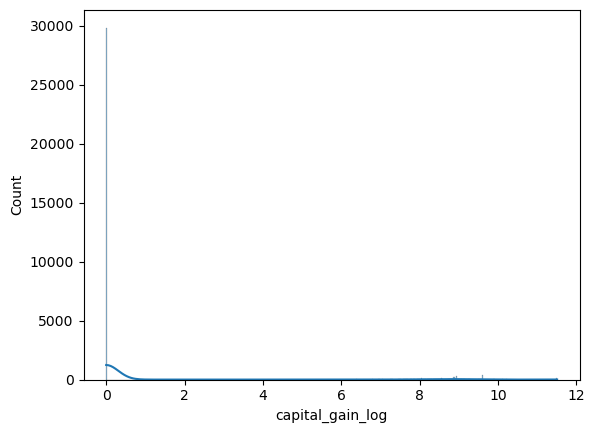

In [44]:
sns.histplot(data = df_encoded , x = "capital_gain_log" , kde = True)
plt.show()

In [45]:
df_encoded.describe()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,"(workclass, _encoded)","(education, _encoded)","(marital_status, _encoded)","(occupation, _encoded)",...,race_ Black,race_ Other,race_ White,sex_ Female,sex_ Male,income_ <=50K,income_ >50K,net_capital,experience_education,capital_gain_log
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,...,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456,3.376371,10.298210,2.611836,6.421762,...,0.095943,0.008323,0.854274,0.330795,0.669205,0.759190,0.240810,990.345014,390.211019,0.734621
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429,1.582038,3.870264,1.506222,4.328619,...,0.294518,0.090851,0.352837,0.470506,0.470506,0.427581,0.427581,7408.986951,176.290905,2.454738
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-4356.000000,19.000000,0.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000,3.000000,9.000000,2.000000,3.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,259.000000,0.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000,3.000000,11.000000,2.000000,6.000000,...,0.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,364.000000,0.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000,3.000000,12.000000,4.000000,10.000000,...,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,495.000000,0.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000,8.000000,15.000000,6.000000,14.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,99999.000000,1350.000000,11.512925


In [46]:
df_encoded['fnlwgt_log'] = np.log1p(df_encoded['fnlwgt'])

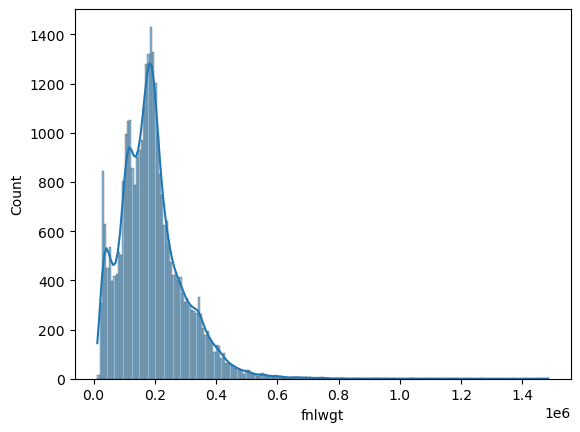

In [48]:
sns.histplot(data = df_encoded , x = "fnlwgt" , kde = True)
plt.show()

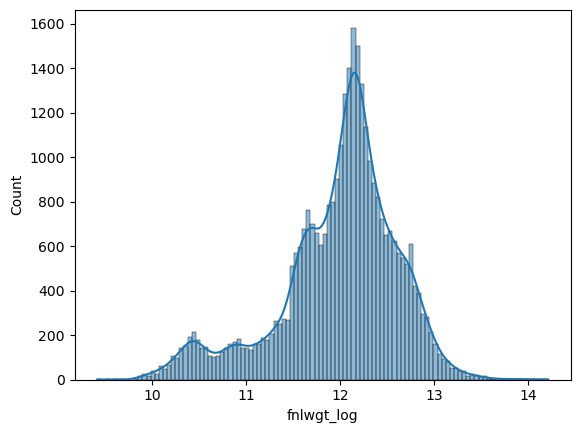

In [49]:
sns.histplot(data = df_encoded , x = "fnlwgt_log" , kde = True)
plt.show()

### Observations

- The `fnlwgt` variable exhibited a positively skewed distribution.
- Additionally, the feature showed a wide range of values, from 12,285 to 1,484,705, indicating the presence of extreme observations and a long right tail.

- A logarithmic transformation was applied to reduce the skewness of the distribution and compress the effect of large values.
- The transformation helps bring the data closer to a normal distribution, reduces the influence of outliers, and improves the effectiveness of machine learning algorithms that are sensitive to highly skewed features.
- As a result, the transformed feature provides a more balanced representation of the data for predictive modeling.